# L3-Mathématiques - Analyse Numérique S1 (LU3MA232)
# TP4: Intégration et interpolation numériques

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# A - Interpolation de Lagrange 

Soient  $a<b$ deux réels. Soit $f : [a, b] \rightarrow \mathbb{R} $ une fonction. Pour tout choix de $n + 1$ points $a = x_0 <
x_1< \cdots < x_n = b$ distincts et tout jeu de $n + 1$ valeurs $f(x_j)$, on appelle polynôme d’interpolation de Lagrange de $f$  aux points $x_j, 0 \leq j \leq n $  l'unique polynôme $P_f$ de degré au plus $n$ défini par :

$$P_f(x)= \sum_{j=0}^{n}f(x_j)\prod_{k\neq j}\left(\frac{x-x_k}{x_j-x_k}\right)=\sum_{j=0}^{n}f(x_j)L_j(x) \mbox{ avec } L_j(x) = \prod_{k\neq j}\left(\frac{x-x_k}{x_j-x_k}\right)$$

On rappelle que $L_j$ est le $j^{ème}$ polynôme de la base de Lagrange associé aux noeuds $[x_0,...,x_n]$. De plus si $f$ est de classe $\mathcal{C}^{n+1}$ on a $\forall x \in [a,b]$ :
$$ |f(x)-P_f(x)|\leq \frac{M_{n+1}}{(n+1)!}|\pi_n(x)| \mbox{ avec }$$

$$ M_{n+1} := \underset{x \in [a,b]}{\sup}|f^{n+1}(x)|,\ \pi_n(x):=(x-x_0)(x-x_1)\cdots(x-x_n)$$

A.1) Écrire une fonction $Lagrange$ qui prend en argument une liste de noeuds $X = [x_0, ..., x_n]$ , un entier $j$ et un réel $x$ et retourne $L_j(x)$ le $j^{ème}$ polynôme de la base de Lagrange évalué en $x$.

In [2]:
def Lagrange(X,j, x):
    L_j = 1
    for k in range(len(X)):
        if (k == j)==True:
            L_j = L_j
        else:
            L_j = L_j * (x - X[k]) / (X[j] - X[k])
    return L_j

In [3]:
#Test 
X = [1, 2 , 3]
print('L_0 (1) = ' , Lagrange(X,0, 1),'; L_0 (2) = ' , Lagrange(X,0, 2) )

L_0 (1) =  1.0 ; L_0 (2) =  -0.0


A.2) Écrire une fonction  $\texttt{P}\_\texttt{f}$  qui prend en argument une fonction $f$, une liste de noeuds $X$ et un réel $x$ et qui renvoie le polynôme d’interpolation de Lagrange de $f$ aux noeuds $X$ évalué au point $x$.

In [4]:
def P_f(f,X, x):
    out = 0
    for j in range(len(X)): 
        out = out + f(X[j]) * Lagrange(X,j, x)
    return out


In [5]:
#Test P_f
def f(x):
    return x**2 + 2*x + 1
X1 = [0, 1]
X2 = [0, 1, 2]

print('P_f(f, X1, -1)  = ', P_f(f, X1, -1), '; P_f(f, X2, -1) =', P_f(f, X2, -1) )


P_f(f, X1, -1)  =  -2.0 ; P_f(f, X2, -1) = 0.0


A.3) Tracer la fonction exponentielle sur l'intervalle $[-2,2]$, ainsi que sur les polynômes d'interpolation de Lagrange à 2,3,4,5 noeuds de la fonction exponentielle (on prendra des noeuds d'interpolation équirépartis sur $[-2,2]$).

In [6]:
def courbe(f,a,b,N,label,ax):
    X = np.linspace(a,b,N)
    Y = [f(x) for x in X]
    ax.plot(X,Y, label = label)
    ax.legend()


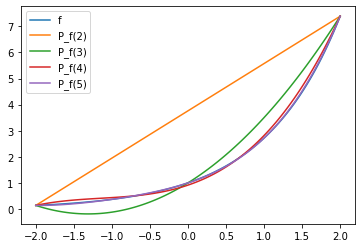

In [7]:
f = lambda x: np.exp(x)      #Assigne la fonction exp(x)
fig = plt.figure()
ax = fig.add_subplot(111)
courbe(f,a=-2,b=2,N=100,label="f",ax=ax)
for n in range(2,6):
    X = list(np.linspace(-2,2,n))
    P = lambda x: P_f(f,X,x)
    N = 100
    courbe(P,a=-2,b=2,N=100,label="P_f({})".format(n),ax=ax)


A.4) Pour chacune des fonctions suivantes, afficher $f$ et son polynôme d'interpolation de Lagrange à 2,3,7,9 noeuds équirépartis sur l'intervalle $[-1,1]$:


$$x \mapsto |x| $$ 

$$x \mapsto \frac{1}{1 + x^2}$$

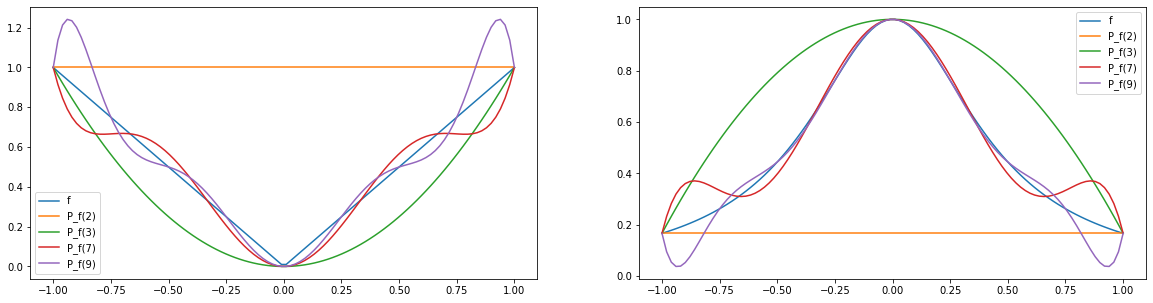

In [8]:
f1 = lambda x : np.abs(x)


def f2(x):
    return 1./(1+5*x**2)

a = -1
b = 1
N = 100


N_int = [2,3,7,9]

fig, ax = plt.subplots(1,2,figsize=(20,5))

courbe(f1,a,b,N,label="f",ax=ax[0])
for n in N_int:
    X = list(np.linspace(-1,1,n))
    P = lambda x: P_f(f1,X,x)
    courbe(P,a,b,N=100,label="P_f({})".format(n),ax=ax[0])
    

courbe(f2,a,b,N,label="f",ax=ax[1])
for n in N_int:
    X = list(np.linspace(-1,1,n))
    P = lambda x: P_f(f2,X,x)
    courbe(P,a,b,N=100,label="P_f({})".format(n),ax=ax[1])



A.5) Qu'observe t-on sur les graphiques?

<font color=red>On voit que pour les fonctions $x \mapsto |x| $ et $x \mapsto \frac{1}{1 + x^2}$ sont mal approchées par leurs polynômes d'interpolation de Lagrange sur la grille uniforme au niveau des extrémités de l'intervalle ( -1  et 1) et que plus on augmente la valeur de $n$ plus le phénomène s'accentue. En effet, on n'a pas nécessairement convergence de $P_f$ vers $f$ lorsque $n \rightarrow +\infty$ car on ne contrôle pas $\pi_n(x)$.



Ce problème est connu sous le nom de $\bf{phénomène\  de \ Runge}$. Pour améliorer cette approximation on doit choisir  une discrétisation qui minimise  $\pi_n(x)$. Il est démontré que ceci est réalisé lorsque les $x_i$ sont les zéros du polynôme de $Tchebychev$ de degré $n+1$, à savoir 

$$x_i = \frac{a+b}{2} + \frac{b-a}{2} \cos\left(\frac{(2i+1)\pi}{2(n+1)}\right),\ i=0,\cdots,n.$$


A.6) Écrire une fonction $\texttt{tchebychev}$ qui prend en argument un entier $n$, deux réels a, b et qui renvoie une liste contenant les $x_i$ zéros du polynôme de $Tchebychev$ de degré $n+1$ sur $[a,b]$.

In [9]:
def tchebychev(n,a,b):
    T = []
    for i in range(n+1):
        T.append((a+b)/2. + (b-a)/2. *np.cos(((2*i+1)*np.pi)/(2*(n+1))))
    return T


A.7) Pour chacune des fonctions suivantes, afficher $f$ et son polynôme d'interpolation de Lagrange à 2,3,7,9 noeuds répartis selon les zéros du polynômes de Tchebytchev (de degrés respectifs 2,3,7,9) sur l'intervalle $[-1,1]$:


$$x \mapsto |x| $$ 

$$x \mapsto \frac{1}{1 + x^2}$$


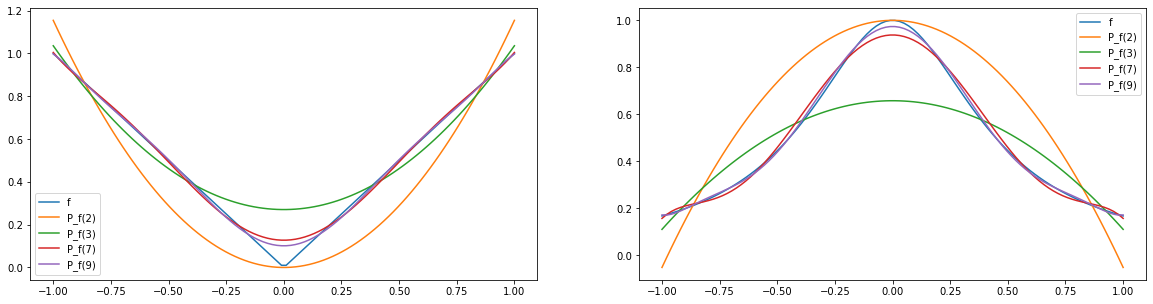

In [10]:
fig, ax = plt.subplots(1,2,figsize=(20,5))

courbe(f1,a,b,N,label="f",ax=ax[0])
for n in N_int:
    X = tchebychev(n, a,b)
    P = lambda x: P_f(f1,X,x)
    courbe(P,a,b,N=100,label="P_f({})".format(n),ax=ax[0])

courbe(f2,a,b,N,label="f",ax=ax[1])
for n in N_int:
    X = tchebychev(n, a,b)
    P = lambda x: P_f(f2,X,x)
    courbe(P,a,b,N=100,label="P_f({})".format(n),ax=ax[1])
    
plt.show()



A.8) Qu'observe t-on pour la fonction $f:\ x \mapsto |x| $ ?


<font color=red>L’approximation de $f$ par $P_f$ n’est pas bonne au voisinage de zéro. 

En effet, on voit bien que la majoration théorique $|f(x)-P_f(x)|$ est fausse puisque $f^{(2)}$ est nulle et donc $M_2 =0$. Ceci ne contredit pas l'approximation théorique car $f$ n'est pas dérivable en 0 et donc la fonction n'est pas $\mathcal{C}^{2}$ sur $[-1,1]$. 

# B - Intégration numérique

Soient $a<b$ deux réels. Soit $f : [a, b] \rightarrow \mathbb{R} $ une fonction continue. On cherche à
calculer une approximation de

$$ \int_a^b\ f(x) dx.$$

## Partie I – Méthode d'interpolation

On approxime la fonction $f$ par un polynôme que l'on intègre.  Nous donnons ici directement la formule obtenue après cette opération d'approximation par un polynôme puis intégration pour 3 méthodes (rectangle à gauche, rectangle point milieu et Simpson). 

**Méthode des rectangles à gauche**

Dans ce cas, on interpole $f$ par un polynôme ne comportant qu'un seul noeud : $a$. On approxime alors l'intégrale par $(b-a) f(a)$. 

B.I.1) Écrire une fonction $\texttt{rectG}$ qui prend en argument une fonction $f$, deux réels $a$, $b$ et qui renvoie l'approximation de la méthode des rectangles gauche sur l'intervalle $[a,b]$. Suite au test, que pouvez vous dire sur l'ordre de la méthode. 

In [11]:
def rectG(f, a,b):
    return f(a)*(b-a)

In [12]:
#Test
P_0 = lambda x : 1
P_1 = lambda x : x

print('rectG(P_0, a = 0,b = 1) = ', rectG(P_0, a = 0,b = 1) , '; rectG(P_1, a = 0,b = 1) =' , rectG(P_1, a = 0,b = 1) )

rectG(P_0, a = 0,b = 1) =  1 ; rectG(P_1, a = 0,b = 1) = 0


**Méthode des rectangles point milieu**

Dans ce cas, on interpole $f$ par un polynôme ne comportant qu'un seul noeud : $\frac{a+b}{2}$. On approxime l'intégrale par $(b-a) f(\frac{a+b}{2})$. 

B.I.2) Écrire une fonction $\texttt{rectM}$ qui prend en argument une fonction $f$, deux réels $a$, $b$ et qui renvoie l'approximation de l'intégrale par la méthode des rectangles point milieu sur l'intervalle $[a,b]$. Suite au test, que pouvez vous dire sur l'ordre de la méthode. 

In [13]:
def rectM(f, a,b):
    return f( (a+b)/2 )*(b-a)

In [14]:
#Test
P_0 = lambda x : 1
P_1 = lambda x : x
P_2 = lambda x : x**2

print('rectM(P_0, a = 0,b = 1) = ', rectM(P_0, a = 0,b = 1) , '; rectM(P_1, a = 0,b = 1) =' , rectM(P_1, a = 0,b = 1), '; rectM(P_2, a = 0,b = 1) =' , rectG(P_2, a = 0,b = 1) )

rectM(P_0, a = 0,b = 1) =  1 ; rectM(P_1, a = 0,b = 1) = 0.5 ; rectM(P_2, a = 0,b = 1) = 0


**Méthode de Simpson**

Dans ce cas, on interpole $f$ par un polynôme ne comportant que trois noeuds : $a$, $\frac{a+b}{2}$, $b$. On approxime l'intégrale par $\frac{(b-a)}{6} \times  \left( f(a) + 4f(\frac{a+b}{2} )+ f(b) \right)$. 

B.I.3) Écrire une fonction $\texttt{Simp}$ qui prend en argument une fonction $f$, deux réels $a$, $b$ et qui renvoie l'approximation de l'intégrale par la méthode de Simpson sur l'intervalle $[a,b]$. Suite au test, que pouvez vous dire sur l'ordre de la méthode. 

In [15]:
def Simp(f, a,b):
    return ( (b-a)/6 ) * (f(a) + 4 *f( (a+b)/2 ) + f(b) )

In [16]:
#Test
P_0 = lambda x : 1
P_1 = lambda x : x
P_2 = lambda x : x**2
P_3 = lambda x : x**3

print('Simp(P_0, a = 0,b = 1) = ', Simp(P_0, a = 0,b = 1) , '; Simp(P_1, a = 0,b = 1) =' , Simp(P_1, a = 0,b = 1))
print('Simp(P_2, a = 0,b = 1) =' , Simp(P_2, a = 0,b = 1), '; Simp(P_3, a = 0,b = 1) =' , Simp(P_3, a = 0,b = 1) )

Simp(P_0, a = 0,b = 1) =  1.0 ; Simp(P_1, a = 0,b = 1) = 0.5
Simp(P_2, a = 0,b = 1) = 0.3333333333333333 ; Simp(P_3, a = 0,b = 1) = 0.25


## Partie II - Méthode d'intégration composite

L'idée est de subdiviser l'intervalle $[a,b]$ en $n$ sous-intervalles de la forme $[x_i, x_{i+1}]$ avec $x_0  = a < x_1 <...< x_n = b$ et d'utiliser la linéarité de l'intégrale. Ensuite, nous utilisons une méthode de type interpollation sur chacun des sous-intervalles $[x_i, x_{i+1}]$ pour approximer l'intégrale. Nous considérons ici que $x_{i+1} - x_i = \frac{b-a}{n}$ ( $ \ \Leftrightarrow \ x_k = a + k \frac{b-a}{n}$)

$$ i.e. \qquad \int_{a}^b f(y) dy  = \underset{ k = 0}{\overset{n-1}{\sum}} \int_{x_k}^{x_{k+1}} f(y)dy \simeq \underset{ k = 0}{\overset{n-1}{\sum}} \int_{x_k}^{x_{k+1}} P_m(f)(y)dy  $$

où $P_m(f)(y)$ est un polynôme d'interpollation de $f$. Notez que la formule pour $\int_{x_k}^{x_{k+1}} P_m(f)(y)dy$ est déterminée par la méthode d'interpollation choisie. 

B.II.1) Ecrire une fonction $\texttt{IntComp}$ qui prend en argument une fonction $f$, deux réels $a$ et $b$, un entier $n$ et une méthode d'intégration de type interpollation $\texttt{meth}$ et qui renvoie $\underset{ k = 0}{\overset{n-1}{\sum}}\int_{x_k}^{x_{k+1}} P_m(f)(y)dy $ où $\int_{x_k}^{x_{k+1}} P_m(f)(y)dy$ est déterminée par $\texttt{meth}$. 

In [17]:
def IntComp(f, a, b, n, meth):
    X = np.linspace(a,b,n)
    I = 0
    for k in range(len(X)-1):
        I = I + meth(f, X[k], X[k+1])
    return I       

In [18]:
#Test 
print(IntComp(P_1, 0, 2, 11, rectG))
print(IntComp(P_1, 0, 2, 11, rectM))
print(IntComp(P_1, 0, 2, 11, Simp))

1.7999999999999998
2.0
2.0


On rappelle que

$$ \int_0^1 \frac{1}{1+x^2} \ dx = \frac{\pi}{4}.$$

B.II.2) Comparer l'erreur (dans une échelle log-log) commise par la fonction $\texttt{IntComp}$ pour chacune des méthodes définies précédement et $n=2,4,8,16,32,64,128$. 

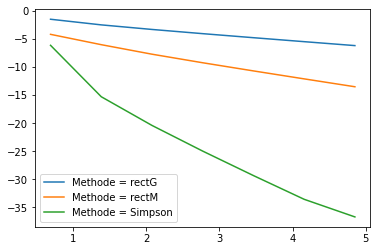

In [19]:
f = lambda x : 1/(1+x**2)
N = [2**(l+1) for l in range(7)]
Meth = [rectG, rectM, Simp]
Title = ['rectG', 'rectM', 'Simpson']
t=0


fig = plt.figure()
ax = fig.add_subplot(111)

for meth in Meth:
    err=[]
    for n in N:
        I = IntComp(f, 0, 1, n, meth)
        e=np.abs( np.pi/4 - I)
        err.append(e)
    plt.plot(np.log(N),np.log(err), label="Methode = {}".format(Title[t]))
    ax.legend()
    t = t+1

## Partie III –  Intégration de Gauss-Legendre

La formule d'intégration est toujours donnée par 
$$ \int_a^b f(x)dx = \underset{k =0}{\overset{N}{\sum}} w_k f(x_k).$$
L'idée, cette fois, est de choisir les poids $w_k$ **et** les noeuds d'interpolations $x_k$ de tels sortes que la formule d'intégration soit exacte pour les polynômes du plus haut degré possible. Nous considérerons ainsi les polynômes de Legendre $P_n$ et la famille de noeuds $(x_k)_{0 \leq k \leq n-1}$ racines du $n^{\text{ème}}$ polynôme de Legendre. 

Les polynômes de Legendre sont définis par la relation de récurrence:


$$ P_{0}(x)=1,\qquad P_{1}(x)=x,\qquad  (n+1)P_{n+1}(x)=(2n+1)xP_{n}(x)-nP_{n-1}(x),$$

$$ P_{n+1}^{'}(x)=P_{n-1}^{'}(x)+(2n+1)P_{n}(x).$$

B.III.1) Écrire une fonction $\texttt{Legendre}$ qui prend un entier $n$ , un réel $x$ et renvoie $P_n(x)$ et sa dérivée $P_{n}^{'}(x)$.

In [4]:
def Legendre(n,x):
     if n==0:
        return 1,0
     else:
        P = np.zeros(n+1)
        DP = np.zeros(n+1)
        P[0],P[1]= 1,x
        DP[0],DP[1]= 0,1
        for k in range(1,n):
            P[k+1] = ((2*k+1)*x*P[k]-k*P[k-1])/(k+1)
            DP[k+1]= DP[k-1]+(2*k+1)*P[k]
        p,dp = P[n],DP[n]
        return p,dp

B.III.2) Écrire une fonction $\texttt{AfficheLegendre}$ qui prend en argument deux entiers $n$, $N$, deux réels $a$, $b$ et qui affiche les $n+1$ premiers polynômes de Legendre sur grille uniforme de $N$ points.

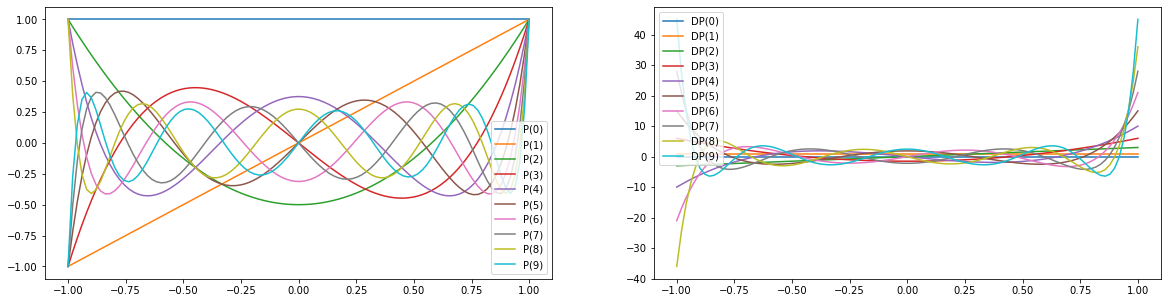

In [9]:
def AfficheLegendre(n,a,b,N):
    fig, ax = plt.subplots(1,2,figsize=(20,5))
    for k in range(n+1):
        courbe(lambda x: Legendre(k,x)[0],a,b,N,"P({})".format(k),ax[0])
        courbe(lambda x: Legendre(k,x)[1],a,b,N,"DP({})".format(k),ax[1])

AfficheLegendre(9,a=-1,b=1,N=100)   

B.III.3) Ecrire une fonction $\texttt{gauss}$ qui prend en argument un entier $n$ et qui renvoie une approximation des $n$ racines du polynôme de Legendre $P_n$ sur un intervalle $[-1, 1]$.

Afin de trouver les points $x_j$ , on va utiliser une méthode de Newton. 

On initialise $x_{j,0} = \cos(\pi \frac{j+\frac{3}{4}}{n + \frac{1}{2}})$ et
on définit 

$$ x_{j,k+1} = x_{j,k} - \frac{P_n(x_{j,k})}{P_n^{'}(x_{j,k})}$$

On s’arrêtera à un indice k tel que $\big|  \frac{P_n(x_{j,k})}{P_n^{'}(x_{j,k})}\big|\leq \varepsilon$ avec la tolérance $\varepsilon$ suffisamment petite et on utilisera l’approximation $x_j\simeq x_{j,k+1}$.

In [22]:
def gauss_j(j,n,eps):
    xj = np.cos(np.pi*((j+(3/4))/(n+(1/2))))
    P,DP = Legendre(n,xj)
    test = P/DP
    while np.abs(test)>eps:
        xj = xj - test
        P,DP = Legendre(n,xj)
        test = P/DP
    return xj

def gauss(n):
    x = np.zeros(n)
    w  =np.zeros(n)
    for j in range(n):
        x[j] = gauss_j(j,n, eps=1e-10)
    return x

B.III.4) Modifier la fonction $\texttt{gauss}$ en une fonction $\texttt{gaussAB}$ qui prend en plus comme argument deux réels $a$, $b$ et un entier naturel $n$ et qui renvoie les points de quadrature de Gauss sur l’intervalle $[a, b]$.

In [23]:
def gaussAB(a,b,n):    
    x = gauss(n)
    x = ((b-a)/2.)*x+((a+b)/2.)
    return x

In [24]:
#Test
gaussAB(n=11,a=0,b=1)

array([0.98911433, 0.9435313 , 0.865076  , 0.75954806, 0.63477158,
       0.5       , 0.36522842, 0.24045194, 0.134924  , 0.0564687 ,
       0.01088567])

B.III.5) Les poids $w_j$ sur $[a,b]$ sont donnés par la formule 
$$  w_j = \frac{(b-a)}{(1-x_j^2)[P_n^{'}(x_j)]^2} $$
(où $x_j$ sont les noeuds d'interpolation précédement calculés).

Ecrire une fonction $\texttt{ PoidsGauss }$ prenant en entrée deux entiers naturels $a$ et $b$ et un entier naturel $n$ et renvoyant une liste contenant les poids $(w_j)_{0\leq j \leq n-1}$ calculés sur l'intervalle $[a,b]$. 

In [25]:
def PoidsGauss(a,b,n):
    X = gauss(n)
    W = np.ones(n)
    for k in range(n):
        P, DP = Legendre(n,X[k])
        W[k] = 2 / ( (1 - X[k]**2) * (DP)**2 )
    W = W * (b-a) / 2.
    return W

PoidsGauss(n=11,a=0,b=1)

array([0.02783428, 0.06279018, 0.09314511, 0.11659688, 0.13140227,
       0.13646254, 0.13140227, 0.11659688, 0.09314511, 0.06279018,
       0.02783428])

B.III.6) Ecrire une fonction $\texttt{MethGauss}$ prenant en entrée une fonction $f$, deux entiers naturels $a$ et $b$ et un entier naturel $n$ (le degré du polynôme utilisé) et calculant l'approximation de l'intégrale par la méthode de Gauss :
$$i.e. \qquad \int_a^b f(x)dx = \underset{k =0}{\overset{N}{\sum}} w_k f(x_k).$$

In [26]:
def MethGauss(f,a,b,n):
    X = gaussAB(a,b,n)
    W = PoidsGauss(a,b,n)
    I = 0
    for k in range(n):
        I +=  W[k]*f(X[k])
    return I

B.III.5) Pour l'application ci-dessous, comparer la précision des différentes méthodes.

$$12\int_{0}^{\frac{1}{2}}\ \sqrt{1-x^{2}}dx\ -\frac{3\sqrt{3}}{2}\ -\ \pi\ =0 $$

In [27]:
def f_test(x):
    return 12* np.sqrt(1-x**2)

print('Méthode des rectangles Gauche : ', abs(IntComp(f_test, 0, 1/2, 5, rectG) - 3 * np.sqrt(3) / 2 - np.pi))
print('Méthode des rectangles Milieu : ', abs( IntComp(f_test, 0, 1/2, 5, rectM) - 3 * np.sqrt(3) / 2 - np.pi))
print('Méthode de Simson : ', abs(IntComp(f_test, 0, 1/2, 5, Simp) - 3 * np.sqrt(3) / 2 - np.pi))
print('Méthode de Gauss : ', abs( MethGauss(f_test,0, 1/2, 5) - 3 * np.sqrt(3) / 2 - np.pi))

Méthode des rectangles Gauche :  0.09147221868894206
Méthode des rectangles Milieu :  0.004499740527062812
Méthode de Simson :  3.082472868065622e-06
Méthode de Gauss :  2.189077363823344e-09
